# Vilkų medžioklės analizė

## Tikslas
Parengti Python aplinką ir Honey Sage diagramų stilių. Tai pradinis projektas; analizės išvadų dar nėra.

## 1. Aplinka
Surandame projekto aplanką ir įjungiame bendrą diagramų stilių.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/chart_style.json").is_file()
             and (p / "Vilkas_analizei_sveikata.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Paleiskite užrašinę projekto aplanke.")
sys.path.insert(0, str(ROOT))
from src.data_loading import load_data, COLUMNS
from src.chart_style import load_chart_style, apply_chart_style, finish_chart

style = load_chart_style(ROOT)
apply_chart_style(style)
print(f"Tema: {style['name']}")
print(f"Python: {sys.version.split()[0]}")

Tema: Honey Sage
Python: 3.14.3


## 2. Duomenų įkėlimas
Naudojami tik 12 pradinių stulpelių ir vienas išvestinis stulpelis iš `Vilkas_analizei_sveikata.csv`. ID ir kitos reikšmės kol kas lieka tekstinės. Tušti laukai nekeičiami į nulį ar FALSE.

In [2]:
data_raw = load_data(ROOT)
print(f"Eilučių: {len(data_raw):,}".replace(",", " "))
print(f"Stulpelių: {len(data_raw.columns)}")
display(data_raw.head(3))

Eilučių: 1 705
Stulpelių: 13


,ID,Medžioklės laikas,Savivaldybė,Medžiojimo būdas,Amžius,Lytis,Ar pažeistas niežų,Ar kiti defektai,sveikatos sutrikimai,Ar priklausė gaujai,"Viso gaujoje, vnt.","Jauniklių gaujoje, vnt.",Geometrija
0,23aaa3e3-3fdd-4fab-a425-5e4152765c7d,2023-12-16T13:40:00,Kelmės r. sav.,varant,Vyresnis nei 1 metų amžiaus,Patinas,FALSE,,FALSE,FALSE,,,POINT (22.41 55.64)
1,d94070e8-d158-43c3-924f-0aa358cc965e,2025-10-19T20:05:00,Anykščių r. sav.,tykojant,Jauniklis iki 1 metų amžiaus,Patelė,FALSE,,FALSE,TRUE,2,0,POINT (25.38 55.54)
2,2df2ff85-5aa1-45dc-af26-41f036b563c5,2025-02-03T16:40:00,Varėnos r. sav.,tykojant,Jauniklis iki 1 metų amžiaus,Patinas,FALSE,,FALSE,TRUE,4,2,POINT (24.79 54.05)


## 3. Techninės patikros
Tikrinama stulpelių tvarka ir lietuviško teksto įkėlimas. Tai nėra išsami duomenų kokybės patikra.

In [3]:
assert list(data_raw.columns) == COLUMNS
assert all(str(dtype) == "string" for dtype in data_raw.dtypes)
assert "Savivaldybė" in data_raw.columns
assert not any("\ufffd" in value for value in data_raw.to_numpy().ravel())
print("Patikros atliktos. Lietuviškos raidės: ą č ę ė į š ų ū ž.")

Patikros atliktos. Lietuviškos raidės: ą č ę ė į š ų ū ž.


## 4. Stiliaus peržiūra
Spalvų juosta skirta tik temai ir lietuviškiems šriftams patikrinti. Ji nerodo analizės rezultatų.

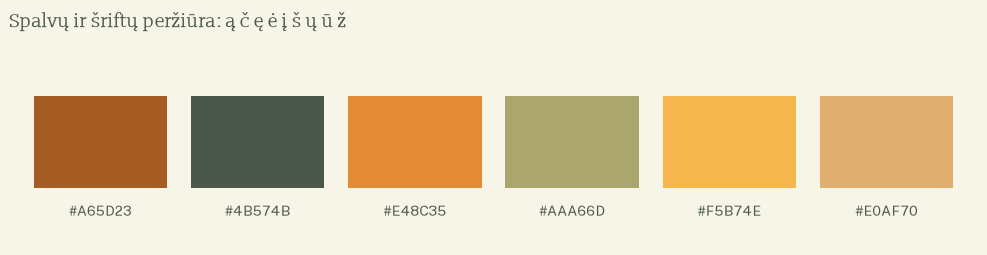

In [4]:
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(10, 2.8))
for index, color in enumerate(style["dataColors"]):
    ax.add_patch(Rectangle((index, 0), 0.85, 0.65, color=color))
    ax.text(index + 0.425, -0.1, color, ha="center", va="top", fontsize=10)
ax.set(xlim=(-0.15, 6), ylim=(-0.4, 1), title="Spalvų ir šriftų peržiūra: ą č ę ė į š ų ū ž")
ax.axis("off")
finish_chart(fig, point_labels=False, zero_reference=False)
fig.savefig(ROOT / "outputs/figures/stiliaus_perziura.png", bbox_inches="tight")
plt.show()

### Sveikatos sutrikimų stulpelis
`sveikatos sutrikimai` gaunamas iš `Ar pažeistas niežų` ir `Ar kiti defektai`: jei bent viena reikšmė TRUE, rezultatas TRUE; jei abi tuščios, rezultatas tuščias; visais kitais atvejais FALSE. Tai naudotojo nustatyta sujungimo taisyklė. Išvestinė FALSE reikšmė savaime nepatvirtina, kad visi pirminiai sveikatos duomenys buvo užpildyti. Ankstesnė CSV versija išsaugota `outputs/backups/Vilkas_analizei_before_sveikatos_sutrikimai.csv`.

## Kitas etapas
Pasirinkti analizės klausimus. Galimos kryptys: įrašai pagal laiką ir savivaldybę, amžių ir lytį, medžiojimo būdą, sveikatos požymius ir priklausymą gaujai.

Prieš skaičiavimus patikrinsime trūkstamas reikšmes, ID pasikartojimus, datų ir skaitinių laukų tinkamumą. Medžioklės sezonų ir geometrijos reikšmės dar nepatvirtintos.